100%|██████████| 170M/170M [40:04<00:00, 70.9kB/s]



SGD with Momentum
Epoch 1: Loss=1.6993, Accuracy=40.13%
Epoch 2: Loss=1.4843, Accuracy=48.21%
Epoch 3: Loss=1.3875, Accuracy=51.71%
Epoch 4: Loss=1.3134, Accuracy=54.27%
Epoch 5: Loss=1.2546, Accuracy=56.50%
Epoch 6: Loss=1.2098, Accuracy=57.87%
Epoch 7: Loss=1.1614, Accuracy=59.63%
Epoch 8: Loss=1.1201, Accuracy=61.29%
Epoch 9: Loss=1.0790, Accuracy=62.55%
Epoch 10: Loss=1.0445, Accuracy=63.96%

Adam Optimizer
Epoch 1: Loss=1.6414, Accuracy=42.55%
Epoch 2: Loss=1.4407, Accuracy=49.58%
Epoch 3: Loss=1.3440, Accuracy=53.25%
Epoch 4: Loss=1.2735, Accuracy=55.82%
Epoch 5: Loss=1.2092, Accuracy=58.07%
Epoch 6: Loss=1.1572, Accuracy=59.73%
Epoch 7: Loss=1.1117, Accuracy=61.46%
Epoch 8: Loss=1.0638, Accuracy=63.12%
Epoch 9: Loss=1.0191, Accuracy=64.48%
Epoch 10: Loss=0.9710, Accuracy=66.29%


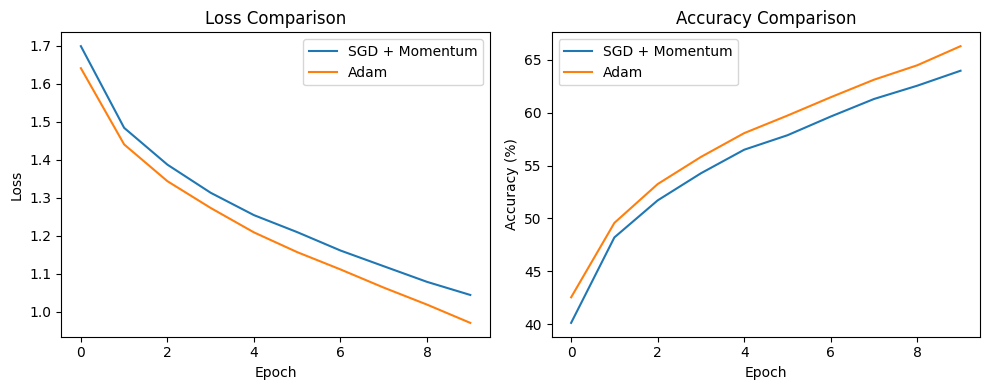

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Dataset
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

trainset = torchvision.datasets.CIFAR10(
    root='./data', train=True,
    transform=transform, download=True
)

trainloader = torch.utils.data.DataLoader(
    trainset, batch_size=128, shuffle=True
)

# MLP Model
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3*32*32, 256),
            nn.ReLU(),
            nn.Linear(256, 10)
        )

    def forward(self, x):
        return self.net(x)

# Training function
def train(model, optimizer, epochs=10):
    model.to(device)
    loss_fn = nn.CrossEntropyLoss()
    losses, accuracies = [], []

    for epoch in range(epochs):
        total_loss = 0
        correct = total = 0

        for imgs, labels in trainloader:
            imgs, labels = imgs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(imgs)
            loss = loss_fn(outputs, labels)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

        loss = total_loss / len(trainloader)
        acc = 100 * correct / total

        losses.append(loss)
        accuracies.append(acc)

        print(f"Epoch {epoch+1}: Loss={loss:.4f}, Accuracy={acc:.2f}%")

    return losses, accuracies

# SGD with Momentum
print("\nSGD with Momentum")
model_sgd = MLP()
sgd = optim.SGD(model_sgd.parameters(), lr=0.01, momentum=0.9)
loss_sgd, acc_sgd = train(model_sgd, sgd)

# Adam
print("\nAdam Optimizer")
model_adam = MLP()
adam = optim.Adam(model_adam.parameters(), lr=0.001)
loss_adam, acc_adam = train(model_adam, adam)

# Loss comparison
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(loss_sgd, label="SGD + Momentum")
plt.plot(loss_adam, label="Adam")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss Comparison")
plt.legend()

# Accuracy comparison
plt.subplot(1, 2, 2)
plt.plot(acc_sgd, label="SGD + Momentum")
plt.plot(acc_adam, label="Adam")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Accuracy Comparison")
plt.legend()

plt.tight_layout()
plt.show()